# 3. Reserves and stability

Tighter gates, other property sets, deleted boreholes and resampled groups.

In [1]:
from evcca.study.diagnostics import TOLSA
from evcca.study.notebook import show_figure, table

## 3.1 Reserves (Fig. 3)

A CV reserve δ requires CV ≤ τ(1 − δ); an extremum reserve η requires ν ≤ ν_crit(m)(1 − η). Every point of the grid is solved over its complete family. Each cell: within-budget specimens and strictly feasible contexts.

In [2]:
grid = table("reserve_grid").query("mode == 'compact'")
cells = grid.groupby(["profile", "method", "cv_reserve", "nu_reserve"]).agg(
    within_budget=("strict_accepted_n", "sum"), strict=("strict_feasible", "sum")
)
cells = cells.within_budget.astype(str) + " (" + cells.strict.astype(str) + ")"
cells.unstack("nu_reserve")

nu_reserve                      0.00      0.01      0.02      0.05
profile method  cv_reserve                                        
four    evcca   0.00        120 (10)  120 (10)  120 (10)  120 (10)
                0.05        120 (10)  120 (10)  120 (10)  120 (10)
                0.10        120 (10)  120 (10)  120 (10)  120 (10)
        ordered 0.00        119 (10)  118 (10)  117 (10)   105 (9)
                0.05        119 (10)  118 (10)   106 (9)    94 (8)
                0.10        119 (10)  118 (10)   106 (9)    94 (8)
nine    evcca   0.00          57 (5)    57 (5)    57 (5)    48 (4)
                0.05          57 (5)    57 (5)    57 (5)    48 (4)
                0.10          57 (5)    57 (5)    57 (5)    47 (4)
        ordered 0.00          57 (5)    57 (5)    57 (5)    48 (4)
                0.05          57 (5)    57 (5)    57 (5)    48 (4)
                0.10          56 (5)    56 (5)    56 (5)    31 (3)

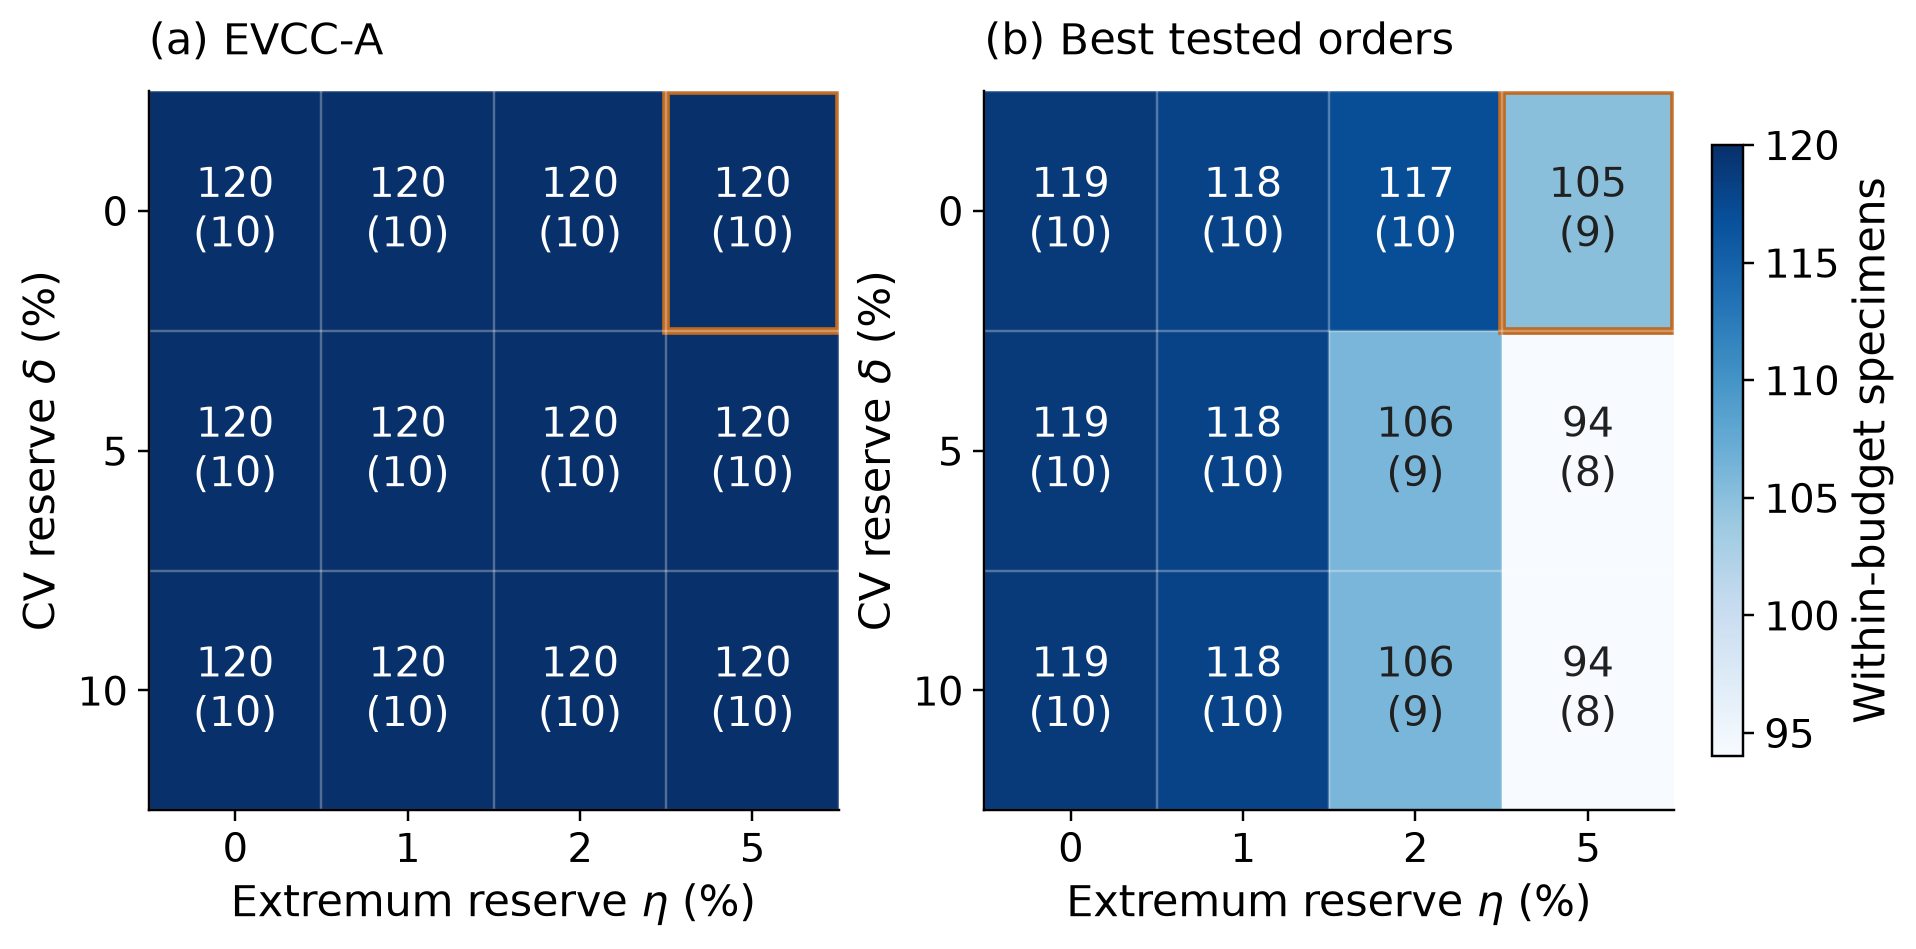

In [3]:
show_figure("fig3_reserve_map")

Tolsa at the nominal CV limits: with a 2 % or 5 % extremum reserve, EVCC-A needs a third group to keep every specimen, while the best order keeps two groups and refers two specimens.

In [4]:
tolsa = grid[grid.context_id.eq(TOLSA) & grid.cv_reserve.eq(0)]
tolsa.pivot(index="nu_reserve", columns="method", values=["A", "K", "strict_feasible"])

A             K         strict_feasible        
method     evcca ordered evcca ordered           evcca ordered
nu_reserve                                                    
0.00           0       1     2       3            True    True
0.01           0       2     2       2            True    True
0.02           0       2     3       2            True    True
0.05           0       2     3       2            True    True

## 3.2 Property profiles (Table 3)

The eleven primary contexts screened with four, seven and nine properties. Each added property is another gate, so fewer contexts are strictly feasible and fewer source units pass.

In [5]:
profiles = table("profile_comparison")
profiles.groupby("profile", sort=False).agg(
    contexts=("context_id", "size"),
    strict=("strict_feasible", "sum"),
    within_budget=("strict_accepted_n", "sum"),
    source_units=("source_units", "sum"),
    source_units_passing=("source_units_passing", "sum"),
)

,contexts,strict,within_budget,source_units,source_units_passing
profile,,,,,
four,11,7,72,29,7
seven,11,6,64,29,6
nine,11,5,57,29,5


## 3.3 Borehole deletion

Every borehole of every context is removed in turn and the context is solved again. A training set below six specimens counts as a failure. The counts are dependent observations of sensitivity, not estimates of a generalization rate.

In [6]:
deletions = table("borehole_deletions")
deletions.groupby(["profile", "cv_reserve", "nu_reserve", "method"]).agg(
    refits=("context_id", "size"), strict=("strict_feasible", "sum")
).unstack("method")

refits         strict        
method                         evcca ordered  evcca ordered
profile cv_reserve nu_reserve                              
four    0.0        0.00          121     121     62      62
                   0.02          121     121     62      62
                   0.05          121     121     58      58
        0.1        0.05          121     121     50      50
nine    0.0        0.00           76      76     29      29
                   0.02           76      76     27      26
                   0.05           76      76     27      26
        0.1        0.05           76      76     25      21

The counts above mix two outcomes. Split by the state before the deletion: `strict_after` among contexts that were strictly feasible keeps feasibility, among the others it gains it. Most losses exceed the review budget by a single specimen.

In [7]:
table("robustness/deletion_outcomes").query("profile == 'four'").drop(columns="profile").set_index(
    ["cv_reserve", "nu_reserve", "method", "strict_before"]
)

deletions  strict_after  too_few_specimens  no_admissible_group  over_budget  over_budget_by_one
cv_reserve nu_reserve method  strict_before                                                                                                  
0.0        0.00       evcca   False                 46             4                  3                   18           21                   7
                              True                  75            58                  2                    2           13                  11
                      ordered False                 46             4                  3                   18           21                   7
                              True                  75            58                  2                    2           13                  11
           0.02       evcca   False                 46             4                  3                   18           21                   6
                              True                  75            58                  2                    2           13                   9
                      ordered False                 46             4                  3                   18           21                   6
                              True                  75            58                  2                    2           13                   9
           0.05       evcca   False                 46             4                  3                   20           19                   6
                              True                  75            54                  2                    3           16                  11
                      ordered False                 53             4                  3                   20           26                   9
                              True                  68            54                  2                    3            9                   8
0.1        0.05       evcca   False                 46             1                  3                   24           18                   4
                              True                  75            49                  2                    3           21                  12
                      ordered False                 64             1                  3                   24           36                  14
                              True                  57            49                  2                    3            3                   2

In [8]:
deletions[deletions.context_id.eq(TOLSA)].pivot(
    index=["cv_reserve", "nu_reserve", "excluded_borehole"], columns="method", values=["A", "K", "strict_feasible"]
)

A             K         strict_feasible        
method                                       evcca ordered evcca ordered           evcca ordered
cv_reserve nu_reserve excluded_borehole                                                         
0.0        0.00       Tolsa, Kirkkonummi::7A     9       9     0       0           False   False
                      Tolsa, Kirkkonummi::7B     4       5     2       1           False   False
                      Tolsa, Kirkkonummi::7C     0       0     2       2            True    True
           0.02       Tolsa, Kirkkonummi::7A     9       9     0       0           False   False
                      Tolsa, Kirkkonummi::7B     4       6     2       1           False   False
                      Tolsa, Kirkkonummi::7C     0       1     2       2            True    True
           0.05       Tolsa, Kirkkonummi::7A     9       9     0       0           False   False
                      Tolsa, Kirkkonummi::7B     4       6     2       1           False   False
                      Tolsa, Kirkkonummi::7C     0       1     3       2            True    True
0.1        0.05       Tolsa, Kirkkonummi::7A     9       9     0       0           False   False
                      Tolsa, Kirkkonummi::7B     5       6     2       1           False   False
                      Tolsa, Kirkkonummi::7C     0       1     3       2            True    True

## 3.4 Tolsa groups: borehole resampling and depth trend

All ordered draws of boreholes with replacement are enumerated (27 for the group from three boreholes, 4 for the group from two), so the percentiles describe a finite conditional distribution, not a population confidence interval.

In [9]:
table("tolsa_block_resampling").round(4)

,group,property,n,boreholes,equiprobable_ordered_draws,cv,p05,p95,exceedance_fraction,limit
0,0,alpha,16,3,27,0.1774,0.1416,0.2004,0.00,0.30
1,0,rho,16,3,27,0.0344,0.0233,0.0396,0.00,0.15
2,0,water_pct,16,3,27,0.1173,0.0761,0.1293,0.00,0.15
3,0,su,16,3,27,0.2338,0.1248,0.2614,0.00,0.30
4,1,alpha,8,2,4,0.2646,0.1165,0.2910,0.00,0.30
5,1,rho,8,2,4,0.0335,0.0278,0.0348,0.00,0.15
6,1,water_pct,8,2,4,0.1403,0.0612,0.1526,0.25,0.15
7,1,su,8,2,4,0.2169,0.0312,0.2169,0.00,0.30


The 16-specimen group passes the CV limit for water content, but its water content falls clearly with depth: the Theil–Sen slope is about −6.6 percentage points per metre over 1.8–5.1 m. No significance test is reported, because the specimens are not independent and the group was selected from the data.

In [10]:
table("tolsa_depth_trend").round(3)

,group,n,boreholes,depth_min,depth_max,water_mean,water_cv,depth_water_spearman,theil_sen_slope_pct_per_m
0,0,16,3,1.845,5.085,58.905,0.117,-0.897,-6.642
1,1,8,2,3.035,5.885,73.548,0.140,0.333,5.193


## 3.5 Returning a deleted borehole

After a borehole is deleted and the context solved again, each held-out specimen joins the group of the nearest-depth training specimen with the same source unit (and fixed unit); its measurements are not used. The augmented groups are then screened again. Counts are specimen appearances over all refits and modes.

In [11]:
returned = table("return_experiment")
returned.groupby(["profile", "method"]).agg(
    held_out=("test_n", "sum"),
    returned=("assigned_new_n", "sum"),
    augmented_groups=("augmented_groups", "sum"),
    failing_groups=("augmented_violating_groups", "sum"),
)

held_out  returned  augmented_groups  failing_groups
profile method                                                       
four    evcca         106        53                33               8
        ordered       106        53                33               8
nine    evcca          70        46                32               8
        ordered        70        46                30               8

In [12]:
returned[returned.assigned_new_n.gt(0)].groupby(["profile", "context_id", "method"])[
    ["test_n", "assigned_new_n", "augmented_groups", "augmented_violating_groups"]
].sum()

test_n  assigned_new_n  augmented_groups  augmented_violating_groups
profile context_id                           method                                                                       
four    FI::Tolsa, Kirkkonummi | CLAY | ILOT evcca         4               4                 2                           2
                                             ordered       4               4                 2                           2
        P09 | LOAM | m | sigma3=50.0         evcca         3               3                 3                           3
                                             ordered       3               3                 3                           3
        PRIMARY::P13 | CLAY | C              evcca        12              12                 9                           0
                                             ordered      12              12                 9                           0
        PRIMARY::P13 | LOAM | C              evcca        34              34                19                           3
                                             ordered      34              34                19                           3
nine    PRIMARY::P13 | CLAY | C              evcca        12              12                 9                           0
                                             ordered      12              12                 9                           0
        PRIMARY::P13 | LOAM | C              evcca        34              34                23                           8
                                             ordered      34              34                21                           8